<div style="text-align: center; margin-bottom: 25px;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/b/b3/Université_Évry_Paris-Saclay_logo.jpg?utm_source=fr.wikipedia.org&utm_campaign=imageinfo&utm_content=original" width="400" style="margin-bottom: 20px;">
    <div style="background-color: #f0f0f0; padding: 15px 25px; border-radius: 12px; width: 60%; margin: auto;">
        <h1 style="margin: 0; font-family: Georgia, serif; color: #000000;">Implémentation de FixMatch sur CIFAR-10 en Python</h1>
        <h3 style="margin: 10px 0 0 0; font-family: Arial, sans-serif; color: #555555; font-weight: normal;">Projet Deep Learning - M2 Data Science</h3>
    </div>
</div>


Réalisé par :

- Timoté RICHARD
- Henri BELLAMY	
- Philippe HUYNH	
- Ziad ABAHAMOU	


### IMPLÉMENTATION DE FIXMATCH SUR MNIST EN PYTORCH

- Ce notebook implémente la méthode semi-supervisée FixMatch (Sohn et al., 2020).
Il contient :
1. Présentation théorique
2. Préparation du jeu de données (MNIST séparé en données étiquetées/non étiquetées)
3. Transformations d'augmentation (weak vs strong)
4. Définition de l'architecture (WideResNet-28-2)
5. Fonction de perte et boucle d'entraînement FixMatch
6. Évaluation et suivi des performances


### 1. Présentation Théorique de FixMatch

FixMatch est une méthode d'apprentissage semi-supervisé (Semi-Supervised Learning - SSL) 
très efficace qui combine deux grands principes :

1. **Le Pseudo-Étiquetage (Pseudo-Labeling) avec Seuil de Confiance :**
   - Pour chaque image non étiquetée $u_b$, on applique une **augmentation faible** $\alpha(u_b)$.
   - Le modèle prédit une distribution de probabilités $q_b = \text{softmax}(f(\alpha(u_b)))$.
   - Si la confiance maximale $\max(q_b)$ dépasse un seuil $\tau$ (par ex. $\tau = 0.95$), 
     on convertit cette prédiction en une étiquette "dur" (one-hot) : $\hat{q}_b = \text{argmax}(q_b)$.
   - Si la confiance est inférieure à $\tau$, l'échantillon est ignoré pour cette itération (masque de confiance).

2. **La Régularisation de Cohérence (Consistency Regularization) :**
   - La même image $u_b$ subit une **augmentation forte** $\mathcal{A}(u_b)$ (ex: RandAugment + Cutout).
   - On calcule la perte d'entropie croisée entre le pseudo-label $\hat{q}_b$ (issu de l'augmentation faible) 
     et la prédiction du modèle sur l'image fortement augmentée $f(\mathcal{A}(u_b))$.

#### Fonction de Perte Globale :
$$L_{total} = L_s + \lambda_u L_u$$

- **Perte supervisée $L_s$ :** Entropie croisée standard sur le petit sous-ensemble étiqueté.
- **Perte non supervisée $L_u$ :**
  $$L_u = \frac{1}{\mu B} \sum_{b=1}^{\mu B} \mathbb{I}(\max(q_b) \ge \tau) H(\hat{q}_b, f(\mathcal{A}(u_b)))$$
  où $\mu$ est le ratio entre le nombre de données non étiquetées et étiquetées par batch, 
  et $\mathbb{I}(\cdot)$ est la fonction indicateur (le masque de confiance).

In [ ]:
# Import
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import copy

In [ ]:
# Reproductibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Sélection automatique du meilleur périphérique disponible (GPU Mac via MPS, GPU Nvidia via CUDA, ou CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Utilisation du périphérique : {device}")

Utilisation du périphérique : mps


In [ ]:
# Hyperparamètres pat défaut
BATCH_SIZE = 64
MU = 7          # Ratio d'images non étiquetées par batch (batch_u = BATCH_SIZE * MU)
TAU = 0.95      # Seuil de confiance
LAMBDA_U = 1.0  # Poids de la perte non supervisée
EPOCHS = 1024    # Nombre d'époques pour MNIST
LR = 0.03       # Taux d'apprentissage initial

### 2. Augmentations de Données (Faible & Forte)

- **Augmentation faible ($\alpha$) :** Flip horizontal aléatoire (50%) + translation aléatoire (crop avec padding de 4 pixels).
- **Augmentation forte ($\mathcal{A}$) :** RandAugment (2 opérations aléatoires avec magnitude donnée) + Cutout.

In [ ]:
# Statistiques spécifiques de normalisation pour MNIST
MNIST_MEAN = (0.1307,)
MNIST_STD = (0.3081,)

In [ ]:
# Transformation faible
transform_weak = transforms.Compose([
    transforms.Pad(2, fill=0),  # Passe de 28x28 à 32x32
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD)
])

In [ ]:
# Transformation forte
transform_strong = transforms.Compose([
    transforms.Pad(2, fill=0),
    transforms.RandomCrop(32, padding=4, padding_mode='reflect'),
    transforms.RandAugment(num_ops=2, magnitude=10),
    transforms.ToTensor(),      # <-- Indispensable ici aussi
    transforms.Normalize(MNIST_MEAN, MNIST_STD)
])

In [ ]:
# Transformation de validation (pas d'augmentation stochastique, juste le padding)
transform_val = transforms.Compose([
    transforms.Pad(2, fill=0),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD)
])

In [ ]:
# Téléchargement des datasets
train_dataset_labeled = datasets.MNIST(root='../data', train=True, download=True, transform=transform_weak)
train_dataset_unlabeled = datasets.MNIST(root='../data', train=True, download=True)
val_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform_val)

In [ ]:
# Sélection stricte de 10 labels par classe (100 au total)
def get_mnist_labeled_unlabeled_splits(dataset, num_labeled_per_class=10):
    targets = np.array(dataset.targets)
    labeled_idxs = []
    
    for c in range(10):
        c_idxs = np.where(targets == c)[0]
        selected = np.random.choice(c_idxs, num_labeled_per_class, replace=False)
        labeled_idxs.extend(selected)
        
    labeled_idxs = np.array(labeled_idxs)
    unlabeled_idxs = np.setdiff1d(np.arange(len(dataset)), labeled_idxs)
    return labeled_idxs, unlabeled_idxs

labeled_idxs, unlabeled_idxs = get_mnist_labeled_unlabeled_splits(train_dataset_labeled, num_labeled_per_class=10)

In [ ]:
print(f"Nombre d'images étiquetées : {len(labeled_idxs)}")
print(f"Nombre d'images non étiquetées : {len(unlabeled_idxs)}")

Nombre d'images étiquetées : 100
Nombre d'images non étiquetées : 59900


### 3. Dataset Personnalisé pour Données Non Étiquetées

Pour les données non étiquetées, nous devons appliquer à la fois la transformation faible 
et la transformation forte sur la même image lors du chargement du batch.

In [ ]:
# Wrapper Dataset pour renvoyer (faible, forte) pour les non-étiquetés
class FixMatchDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, transform_weak, transform_strong):
        self.dataset = dataset
        self.transform_weak = transform_weak
        self.transform_strong = transform_strong

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, target = self.dataset[idx]
        
        # Application des transformations
        img_w = self.transform_weak(img)
        img_s = self.transform_strong(img)
        
        return (img_w, img_s), target

### 4. Partitionnement des Données (Supervisé / Non Supervisé)

On extrait un petit nombre d'images étiquetées (ex: 250 images au total, soit 25 par classe pour CIFAR-10) 
et le reste constitue le jeu non étiqueté.

In [ ]:
# Datasets PyTorch
labeled_subset = Subset(train_dataset_labeled, labeled_idxs)
unlabeled_subset_raw = Subset(train_dataset_unlabeled, unlabeled_idxs)
unlabeled_dataset = FixMatchDataset(unlabeled_subset_raw, transform_weak, transform_strong)

In [ ]:
# DataLoaders
labeled_loader = DataLoader(labeled_subset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=BATCH_SIZE * MU, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=100, shuffle=False)

### 5. Architecture du Modèle (Wide ResNet 28-2)

FixMatch utilise couramment WideResNet-28-2 pour CIFAR-10. 
Voici une version compacte du WideResNet.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, in_planes, out_planes, stride, drop_rate=0.0):
        super(BasicBlock, self).__init__()
        self.bn1 = nn.BatchNorm2d(in_planes)
        self.relu1 = nn.ReLU(inplace=True)
        self.conv1 = nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_planes)
        self.relu2 = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_planes, out_planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.drop_rate = drop_rate
        self.equalInOut = (in_planes == out_planes)
        self.convShortcut = (not self.equalInOut) and nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, padding=0, bias=False) or None

    def forward(self, x):
        if not self.equalInOut:
            x = self.relu1(self.bn1(x))
            out = self.conv1(x)
        else:
            out = self.relu1(self.bn1(x))
            out = self.conv1(out)
        if self.drop_rate > 0:
            out = F.dropout(out, p=self.drop_rate, training=self.training)
        out = self.conv2(self.relu2(self.bn2(out)))
        return torch.add(self.convShortcut(x) if self.convShortcut is not None else x, out)

In [ ]:
class NetworkBlock(nn.Module):
    def __init__(self, nb_layers, in_planes, out_planes, block, stride=1, drop_rate=0.0):
        super(NetworkBlock, self).__init__()
        self.layer = self._make_layer(block, in_planes, out_planes, nb_layers, stride, drop_rate)

    def _make_layer(self, block, in_planes, out_planes, nb_layers, stride, drop_rate):
        layers = []
        for i in range(int(nb_layers)):
            layers.append(block(i == 0 and in_planes or out_planes, out_planes, i == 0 and stride or 1, drop_rate))
        return nn.Sequential(*layers)

    def forward(self, x):
        return self.layer(x)

In [ ]:
class WideResNet(nn.Module):
    def __init__(self, depth=28, widen_factor=2, num_classes=10, drop_rate=0.0):
        super(WideResNet, self).__init__()
        nChannels = [16, 16 * widen_factor, 32 * widen_factor, 64 * widen_factor]
        assert (depth - 4) % 6 == 0, "Depth should be 6n+4"
        n = (depth - 4) // 6
        block = BasicBlock
        
        # MODIFICATION CLÉ POUR MNIST : in_channels=1 au lieu de 3
        self.conv1 = nn.Conv2d(1, nChannels[0], kernel_size=3, stride=1, padding=1, bias=False)
        
        self.block1 = NetworkBlock(n, nChannels[0], nChannels[1], block, 1, drop_rate)
        self.block2 = NetworkBlock(n, nChannels[1], nChannels[2], block, 2, drop_rate)
        self.block3 = NetworkBlock(n, nChannels[2], nChannels[3], block, 2, drop_rate)
        
        self.bn1 = nn.BatchNorm2d(nChannels[3])
        self.relu = nn.ReLU(inplace=True)
        self.fc = nn.Linear(nChannels[3], num_classes)
        self.nChannels = nChannels[3]

    def forward(self, x):
        out = self.conv1(x)
        out = self.block1(out)
        out = self.block2(out)
        out = self.block3(out)
        out = self.relu(self.bn1(out))
        out = F.adaptive_avg_pool2d(out, 1)
        out = out.view(-1, self.nChannels)
        return self.fc(out)


In [ ]:
# Instanciation du modèle WRN-28-2
model = WideResNet(depth=28, widen_factor=2, num_classes=10).to(device)
print(f"Nombre de paramètres du modèle : {sum(p.numel() for p in model.parameters()):,}")

Nombre de paramètres du modèle : 1,467,322


### 6. Hyperparamètres & Optimiseur

Conformément à l'article FixMatch :
- **Optimiseur :** SGD avec Nesterov Momentum (0.9), Weight Decay ($5 \times 10^{-4}$).
- **Scheduler :** Cosine Annealing.
- **Seuil de confiance $\tau$ :** 0.95.
- **Poids de la perte non supervisée $\lambda_u$ :** 1.0.

In [ ]:
optimizer = torch.optim.SGD(
    model.parameters(), 
    lr=LR, 
    momentum=0.9, 
    nesterov=True, 
    weight_decay=5e-4
)

In [ ]:
# Cosine Annealing Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

### 7. Boucle d'Entraînement FixMatch

In [ ]:
def train_one_epoch(model, labeled_loader, unlabeled_loader, optimizer, device, tau=0.95, lambda_u=1.0):
    model.train()
    
    labeled_iter = iter(labeled_loader)
    unlabeled_iter = iter(unlabeled_loader)
    
    total_loss_sum = 0.0
    total_loss_s = 0.0
    total_loss_u = 0.0
    mask_count = 0
    total_unlabeled = 0
    
    num_batches = len(labeled_loader)
    
    for _ in range(num_batches):
        try:
            inputs_x, targets_x = next(labeled_iter)
        except StopIteration:
            labeled_iter = iter(labeled_loader)
            inputs_x, targets_x = next(labeled_iter)
            
        try:
            (inputs_u_w, inputs_u_s), _ = next(unlabeled_iter)
        except StopIteration:
            unlabeled_iter = iter(unlabeled_loader)
            (inputs_u_w, inputs_u_s), _ = next(unlabeled_iter)
            
        batch_size_x = inputs_x.shape[0]
        batch_size_u = inputs_u_w.shape[0]
        
        inputs_x = inputs_x.to(device)
        targets_x = targets_x.to(device)
        inputs_u_w = inputs_u_w.to(device)
        inputs_u_s = inputs_u_s.to(device)
        
        inputs = torch.cat((inputs_x, inputs_u_w, inputs_u_s), dim=0)
        logits = model(inputs)
        
        logits_x = logits[:batch_size_x]
        logits_u_w = logits[batch_size_x:batch_size_x + batch_size_u]
        logits_u_s = logits[batch_size_x + batch_size_u:]
        
        # 1. Perte Supervisée
        loss_s = F.cross_entropy(logits_x, targets_x)
        
        # 2. Perte Non Supervisée (FixMatch)
        with torch.no_grad():
            probs_u_w = torch.softmax(logits_u_w, dim=1)
            max_probs, pseudo_label = torch.max(probs_u_w, dim=1)
            mask = max_probs.ge(tau).float()
            
        loss_u = (F.cross_entropy(logits_u_s, pseudo_label, reduction='none') * mask).mean()
        
        # Perte Totale
        loss = loss_s + lambda_u * loss_u
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss_sum += loss.item()
        total_loss_s += loss_s.item()
        total_loss_u += loss_u.item()
        mask_count += mask.sum().item()
        total_unlabeled += batch_size_u
        
    mask_rate = mask_count / total_unlabeled
    return total_loss_sum / num_batches, total_loss_s / num_batches, total_loss_u / num_batches, mask_rate

In [ ]:
def evaluate(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    return 100 * correct / total

### 8. Lancement de l'Entraînement

In [ ]:
history = {'loss': [], 'loss_s': [], 'loss_u': [], 'mask_rate': [], 'val_acc': []}

for epoch in range(EPOCHS):
    loss, loss_s, loss_u, mask_rate = train_one_epoch(
        model, labeled_loader, unlabeled_loader, optimizer, device, tau=TAU, lambda_u=LAMBDA_U
    )
    scheduler.step()
    
    val_acc = evaluate(model, val_loader, device)
    
    history['loss'].append(loss)
    history['loss_s'].append(loss_s)
    history['loss_u'].append(loss_u)
    history['mask_rate'].append(mask_rate)
    history['val_acc'].append(val_acc)
    
    if (epoch + 1) % 10 == 0 or epoch == EPOCHS - 1:
        print(f"Époque [{epoch+1:03d}/{EPOCHS}] | Perte Totale: {loss:.4f} | Perte Sup: {loss_s:.4f} | "
              f"Perte Non-Sup: {loss_u:.4f} | Taux Masque (>=0.95): {mask_rate*100:.1f}% | Précision Val: {val_acc:.2f}%")
        

Époque [010/100] | Perte Totale: 2.0274 | Perte Sup: 2.0274 | Perte Non-Sup: 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 11.35%
Époque [020/100] | Perte Totale: 1.3558 | Perte Sup: 1.3558 | Perte Non-Sup: 0.0000 | Taux Masque (>=0.95): 0.0% | Précision Val: 11.35%
Époque [030/100] | Perte Totale: 0.8738 | Perte Sup: 0.8735 | Perte Non-Sup: 0.0003 | Taux Masque (>=0.95): 0.2% | Précision Val: 10.56%
Époque [040/100] | Perte Totale: 0.1846 | Perte Sup: 0.1336 | Perte Non-Sup: 0.0510 | Taux Masque (>=0.95): 12.7% | Précision Val: 66.64%
Époque [050/100] | Perte Totale: 0.1619 | Perte Sup: 0.0342 | Perte Non-Sup: 0.1277 | Taux Masque (>=0.95): 36.2% | Précision Val: 84.12%
Époque [060/100] | Perte Totale: 0.1307 | Perte Sup: 0.0166 | Perte Non-Sup: 0.1140 | Taux Masque (>=0.95): 49.3% | Précision Val: 74.52%
Époque [070/100] | Perte Totale: 0.0896 | Perte Sup: 0.0156 | Perte Non-Sup: 0.0741 | Taux Masque (>=0.95): 50.0% | Précision Val: 75.57%
Époque [080/100] | Perte Totale: 0.07

### 9. Visualisation des Courbes d'Apprentissage

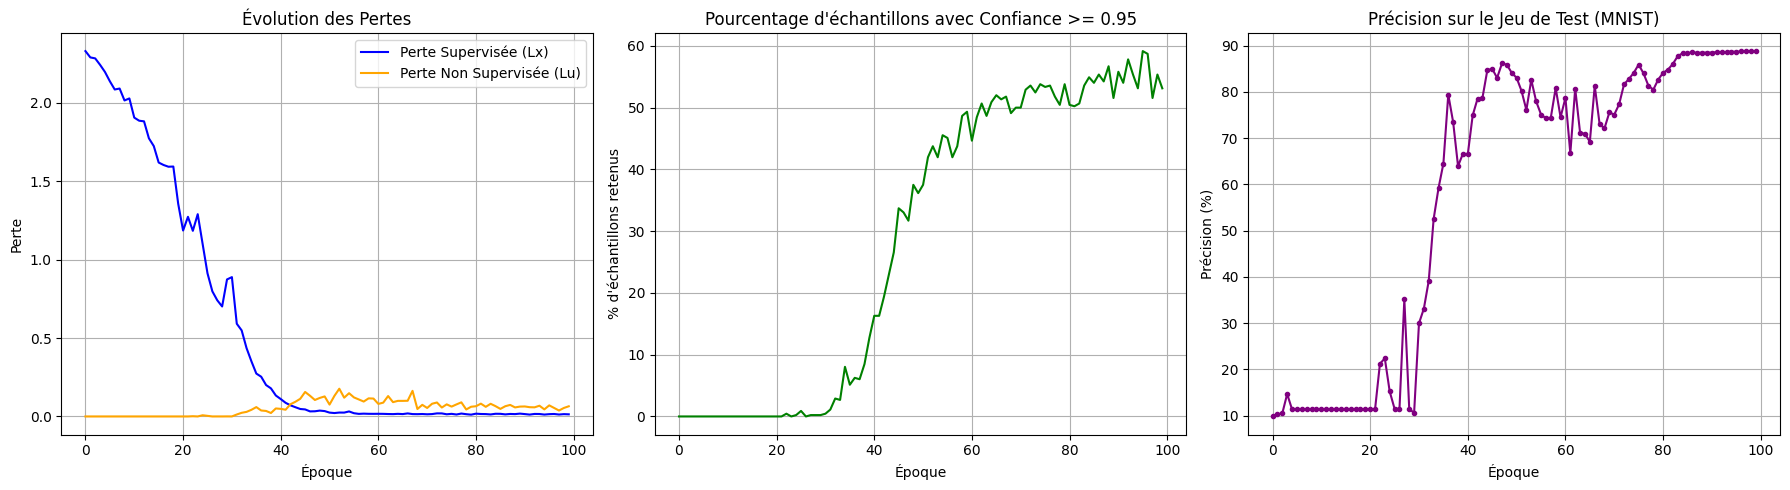

In [ ]:
# Traçage des courbes
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].plot(history['loss_s'], label='Perte Supervisée (Lx)', color='blue')
axs[0].plot(history['loss_u'], label='Perte Non Supervisée (Lu)', color='orange')
axs[0].set_title('Évolution des Pertes')
axs[0].set_xlabel('Époque')
axs[0].set_ylabel('Perte')
axs[0].legend()
axs[0].grid(True)

axs[1].plot([m * 100 for m in history['mask_rate']], color='green')
axs[1].set_title(f'Pourcentage d\'échantillons avec Confiance >= {TAU}')
axs[1].set_xlabel('Époque')
axs[1].set_ylabel('% d\'échantillons retenus')
axs[1].grid(True)

axs[2].plot(history['val_acc'], color='purple', marker='o', markersize=3)
axs[2].set_title('Précision sur le Jeu de Test (MNIST)')
axs[2].set_xlabel('Époque')
axs[2].set_ylabel('Précision (%)')
axs[2].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Évaluation finale détaillée (Classification Report & Matrice de confusion)
CLASSES_MNIST = [str(i) for i in range(10)]

Accuracy Globale        : 88.77%
Precision (Macro Avg)  : 89.24%
Recall    (Macro Avg)  : 88.54%
F1-Score  (Macro Avg)  : 88.56%
------------------------------------------------------------

--- Rapport détaillé par classe ---
              precision    recall  f1-score   support

           0     0.8636    0.9173    0.8897       980
           1     0.9885    0.9850    0.9868      1135
           2     0.9172    0.7510    0.8258      1032
           3     0.7975    0.9317    0.8594      1010
           4     0.8954    0.9501    0.9219       982
           5     0.9475    0.7892    0.8612       892
           6     0.9178    0.8507    0.8830       958
           7     0.8441    0.9377    0.8885      1028
           8     0.9274    0.8131    0.8665       974
           9     0.8254    0.9277    0.8735      1009

    accuracy                         0.8877     10000
   macro avg     0.8924    0.8854    0.8856     10000
weighted avg     0.8928    0.8877    0.8870     10000



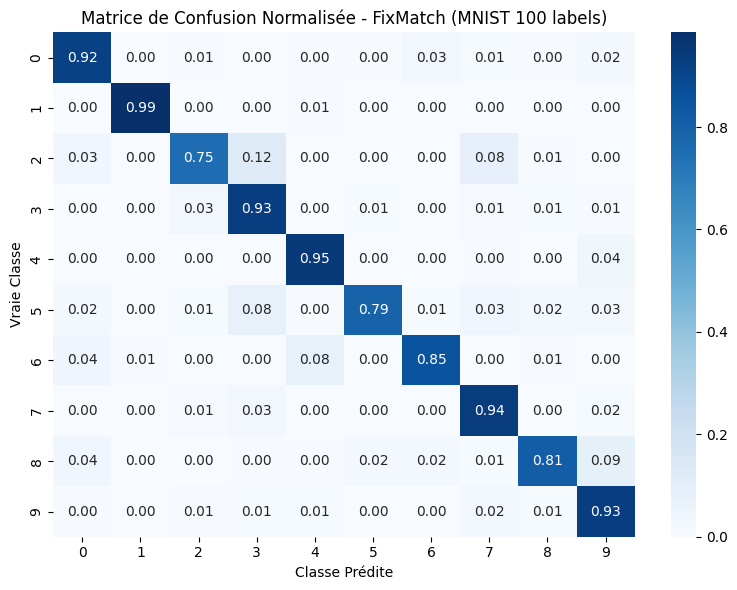

In [ ]:
def detailed_evaluation(model, val_loader, device, classes):
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    acc = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro')
    
    print(f"Accuracy Globale        : {acc * 100:.2f}%")
    print(f"Precision (Macro Avg)  : {precision * 100:.2f}%")
    print(f"Recall    (Macro Avg)  : {recall * 100:.2f}%")
    print(f"F1-Score  (Macro Avg)  : {f1 * 100:.2f}%")
    print("-" * 60)
    print("\n--- Rapport détaillé par classe ---")
    print(classification_report(all_targets, all_preds, target_names=classes, digits=4))
    
    cm = confusion_matrix(all_targets, all_preds)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title('Matrice de Confusion Normalisée - FixMatch (MNIST 100 labels)')
    plt.xlabel('Classe Prédite')
    plt.ylabel('Vraie Classe')
    plt.tight_layout()
    plt.show()

detailed_evaluation(model, val_loader, device, CLASSES_MNIST)

### 10. Conclusion et Bilan du Projet

Ce projet a permis d'implémenter et d'évaluer de bout en bout la méthode **FixMatch** (Sohn et al., 2020), une approche de référence en apprentissage semi-supervisé (Semi-Supervised Learning).

#### Synthèse des Résultats :

1. Analyse des Courbes et Dynamique d'Apprentissage

- **Évolution de la Précision** :

Entraîné sur un sous-ensemble extrêmement restreint de seulement 100 images étiquetées (soit 10 images par classe) sur les 60 000 images du jeu de données MNIST, le modèle WideResNet-28-2 atteint une excellente précision globale de 88.77% (avec un F1-score macro de 88.56%). La courbe de validation montre une phase initiale d'exploration (~10-15% de précision, équivalent à un choix aléatoire pendant les 30 premières époques), suivie d'une transition abrupte (amorçage du pseudo-étiquetage) autour de l'époque 40, pour converger vers un plateau stable proche de 88.8%.

- **Taux de Masque de Confiance (τ≥0.95)** :

Le pourcentage d'échantillons non étiquetés retenus illustre parfaitement le mécanisme de bootstrap de FixMatch. Il reste proche de 0% au début de l'entraînement (le modèle n'étant pas encore assez confiant), puis croît de manière fulgurante entre l'époque 30 et l'époque 60 pour se stabiliser entre 50% et 55%. Plus de la moitié des données non étiquetées sont ainsi exploitées de manière autonome avec une très haute certitude (≥95%).

- **Évolution des Pertes** :

La perte supervisée ($L_x$) chute rapidement à mesure que le réseau s'approprie les 100 exemples étiquetés, tandis que la perte non supervisée ($L_u$) se stabilise après une phase de transition, traduisant l'efficacité de la régularisation de cohérence entre augmentations faibles et fortes (RandAugment).

2. Analyse Détaillée par Classe (Matrice de Confusion)
   
- **Performances remarquables** :

Le modèle reconnaît avec une précision et un rappel spectaculaires le chiffre 1 (rappel de 98.5%, précision de 98.8%, score diagonal à 0.99) ainsi que le chiffre 7 (94% de reconnaissance correcte) et le chiffre 4 (95%). Ces chiffres possèdent des tracés géométriques très distincts et faciles à isoler.

- **Confusions principales** :

> Le chiffre 2 est parfois confondu avec le chiffre 3 (12% des cas), en raison de similarités structurelles dans les boucles et les courbures.

> Le chiffre 5 présente une confusion notable avec le chiffre 3 (8%).

> Le chiffre 8 est le plus délicat, avec des confusions notables vers le 9 (9%) et le 0 (4%), ce qui s'explique par la complexité de sa topologie fermée et le très faible nombre d'exemples de référence initiaux (seulement 10 par classe).

3. Bilan et Apport du Semi-Supervisé

- **Efficacité redoutable sur MNIST** :

Obtenir près de 88.8% de précision avec seulement 10 images par classe démontre la puissance de l'approche semi-supervisée FixMatch. Un modèle supervisé classique confiné à ce volume de données minuscule se serait heurté à un surapprentissage (overfitting) immédiat et drastique.

- **Perspectives d'amélioration** :

Pousser l'entraînement vers un plus grand nombre d'époques (par exemple 200 ou 500 époques) ou ajuster le seuil de confiance τ permettrait probablement d'optimiser encore la convergence et de franchir un palier supérieur de performance sur les chiffres présentant des confusions sémantiques.